# Model validation of water levels

Note: this notebook requires the model output data

In [1]:
import mikeio
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd

In [2]:
ms.options.metrics.list = ["urmse", "mae", "cc", "si", "r2"]

In [3]:
# mr_fldr = "../output_sample/"
mr_fldr = '\\\\DKCPH1-STOR.DHI.DK\\Projects\\11561006\\WaterBench\\WaterBench-MIKE3HD-Oresund\\output\\2024\\'.replace("\\","/") # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

Model results data are stored in a dfs0 file. We can use [MIKE IO](https://dhi.github.io/mikeio) read the data to a MIKE IO Dataset.


In [4]:
ds = mikeio.read(f"{mr_fldr}2D.dfsu", items="*Surf*")
ds.items

[Surface elevation <Surface Elevation> (meter)]

Load water level data

In [5]:
obs_fldr = "../observations/" 
df_stn = pd.read_csv(obs_fldr + "stations.csv", index_col=0)

q = ms.Quantity(name="Surface Elevation", unit="meter")
wllist = []
for i, row in df_stn.iterrows():
    df = pd.read_csv(obs_fldr + f"{i}_wl.csv", index_col=0)
    df.index = pd.to_datetime(df.index, format="ISO8601")
    o = ms.PointObservation(df.water_level, x=row['easting_m'], y=row['northing_m'], name=i, quantity=q)
    wllist.append(o)

In [6]:
df

,water_level
datetime_UTC,
2014-07-10 08:30:00,0.17
2014-07-10 09:00:00,0.17
2014-07-10 09:30:00,0.15
2014-07-10 10:00:00,0.14
2014-07-10 10:30:00,0.11
...,...
2019-01-01 23:00:00,0.83
2019-01-01 23:30:00,0.90
2019-01-02 00:00:00,0.93


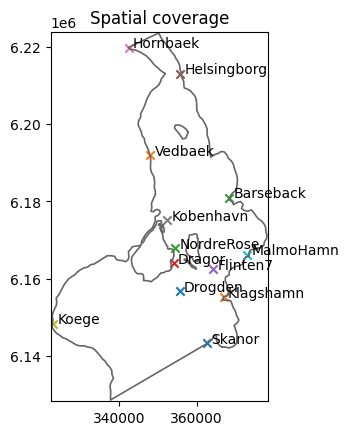

In [7]:
msh = mikeio.open("../input/oresund.mesh")
ms.plotting.spatial_overview(wllist, mod=msh);

In [8]:
cmps = []
da = ds[0]
model_time = pd.DatetimeIndex(ds.time.to_pydatetime())
model_values = da.to_numpy()

for o in wllist:
    # Extract nearest model element and build a point model result
    eid = da.geometry.find_index(coords=(o.x, o.y))[0]
    mser = pd.Series(model_values[:, eid], index=model_time)
    pmr = ms.PointModelResult(mser, x=o.x, y=o.y, name="MIKE3")

    try:
        cmp = ms.match(obs=o, mod=pmr, obs_no_overlap="warn")
        if cmp is not None:
            cmps.append(cmp.remove_bias())
    except Exception as e:
        print(f"{o.name}: {e}")

cc = ms.ComparerCollection(cmps)

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\timeseries\_timeseries.py:339: UserWarning: No data left after trimming to 2023-12-31 23:59:59 - 2024-12-31 23:00:01
  warnings.warn(msg)


<Axes: >

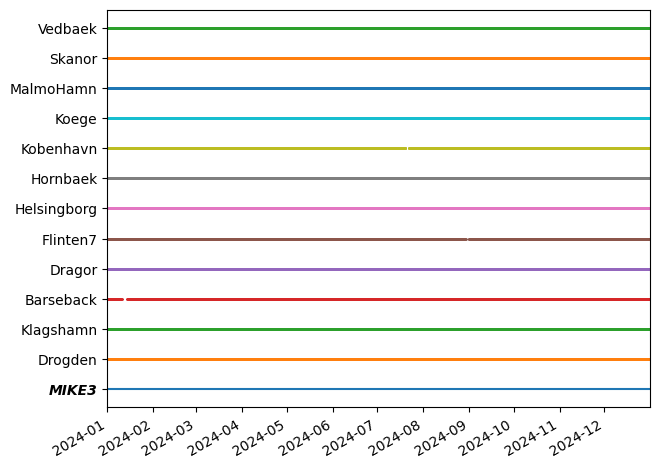

In [9]:
cc.plot.temporal_coverage()

## Skill table

In [10]:
cc.skill().round(3)

,n,urmse,mae,cc,si,r2
observation,,,,,,
Drogden,17337,0.120,0.092,0.876,0.712,0.567
Klagshamn,8769,0.123,0.094,0.881,0.530,0.505
Barseback,8589,0.130,0.098,0.787,0.625,0.327
Dragor,17404,0.122,0.093,0.826,0.651,0.309
Flinten7,8242,0.134,0.100,0.785,0.656,0.045
Helsingborg,8734,0.120,0.094,0.846,0.624,0.434
Hornbaek,17189,0.133,0.105,0.898,0.726,0.638
Kobenhavn,16889,0.133,0.102,0.797,0.524,0.326
Koege,17367,0.126,0.096,0.872,0.619,0.613


## Example timeseries

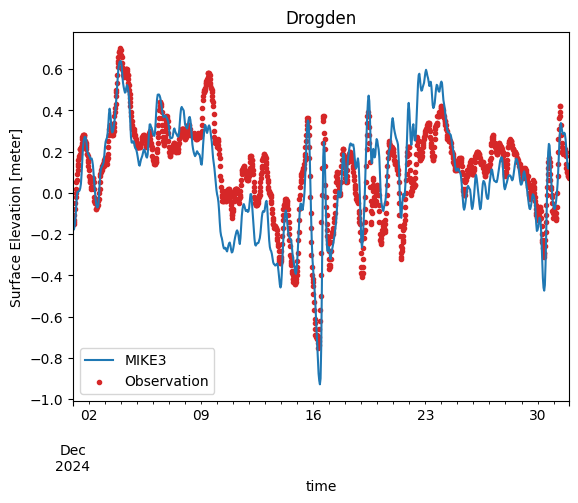

In [11]:
plot_all = False
if not plot_all:
    cc["Drogden"].sel(time=slice("2024-12-01","2024-12-31")).plot.timeseries();
else:
    for cmp in cc:
        cmp.sel(time=slice("2024-12-01","2024-12-31")).plot.timeseries();
        if save_png:
            plt.savefig(f"{fig_fldr}modelskill_timeseries_{cmp.name}.png", bbox_inches='tight');

## Scatter plots

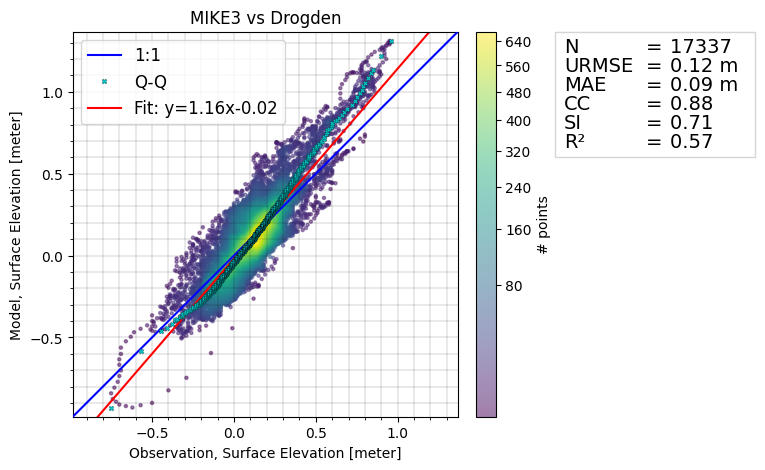

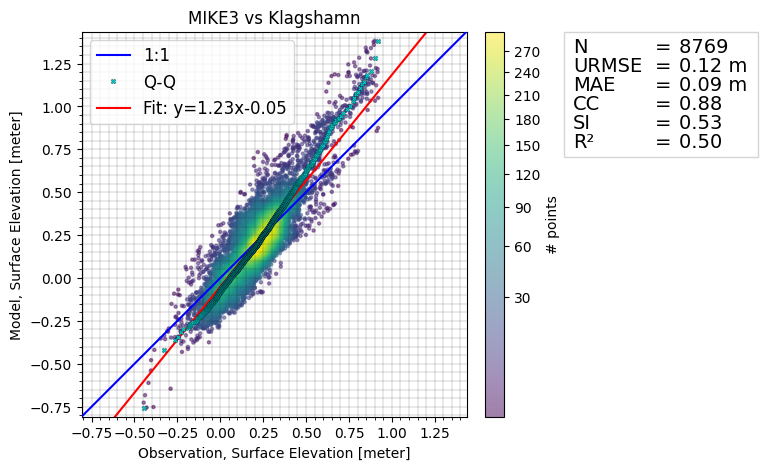

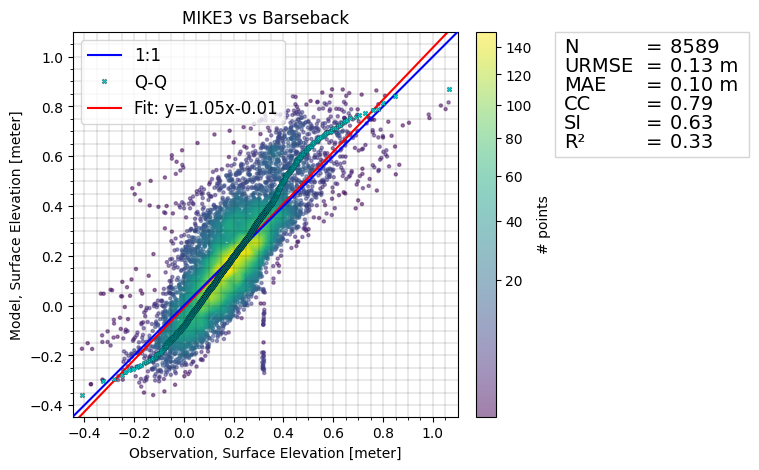

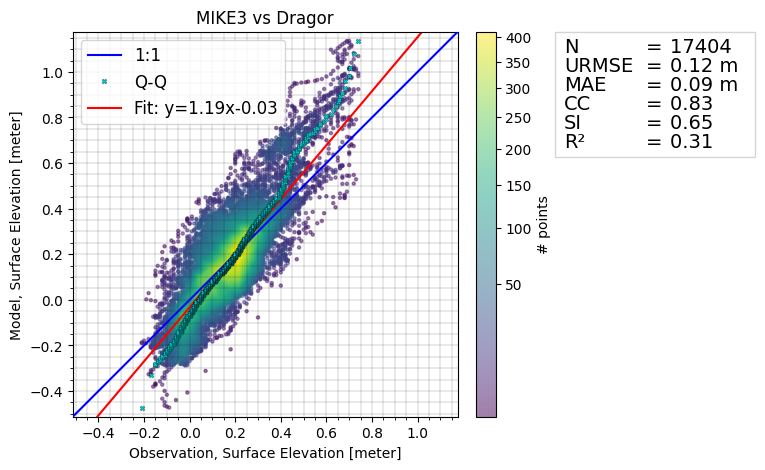

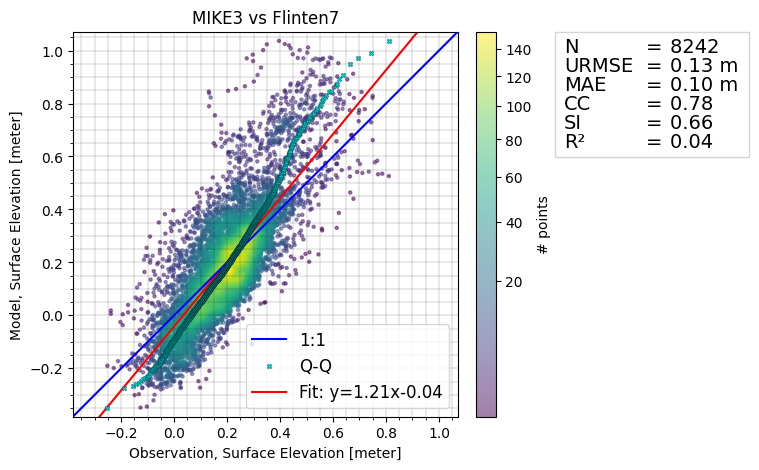

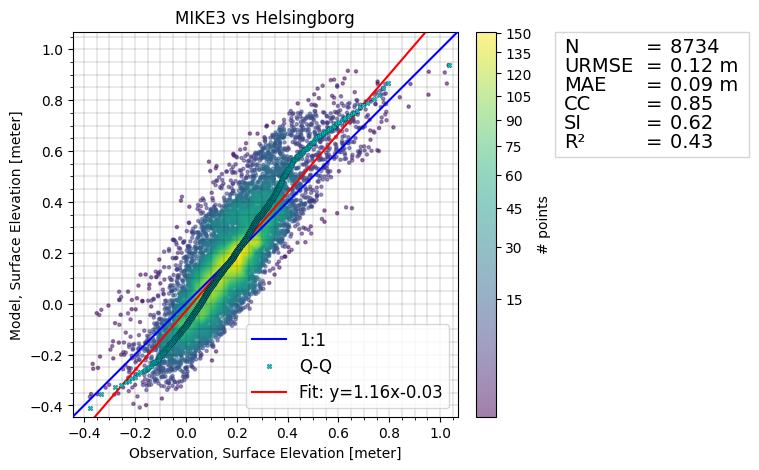

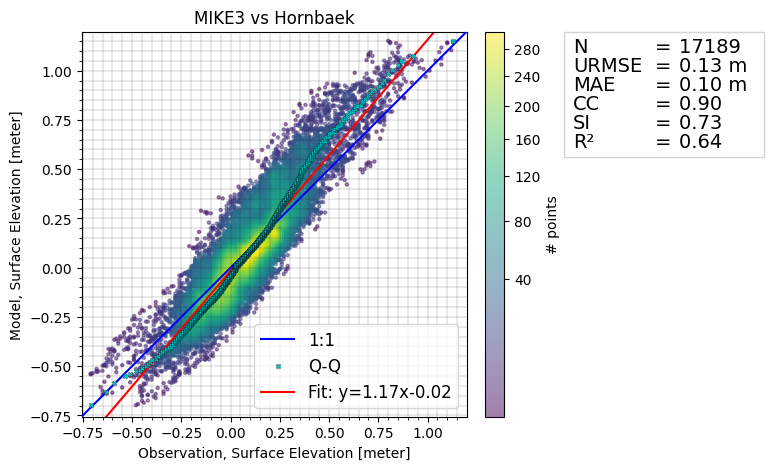

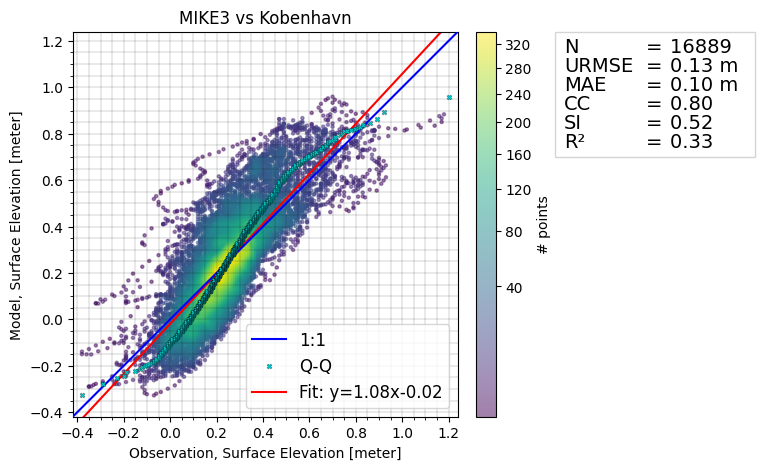

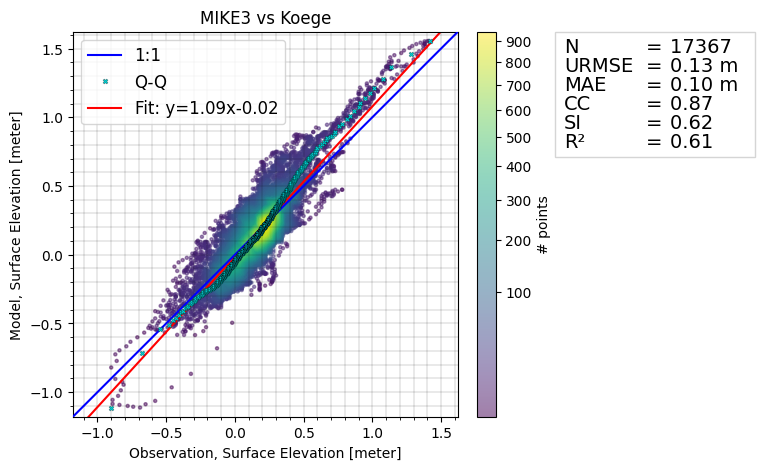

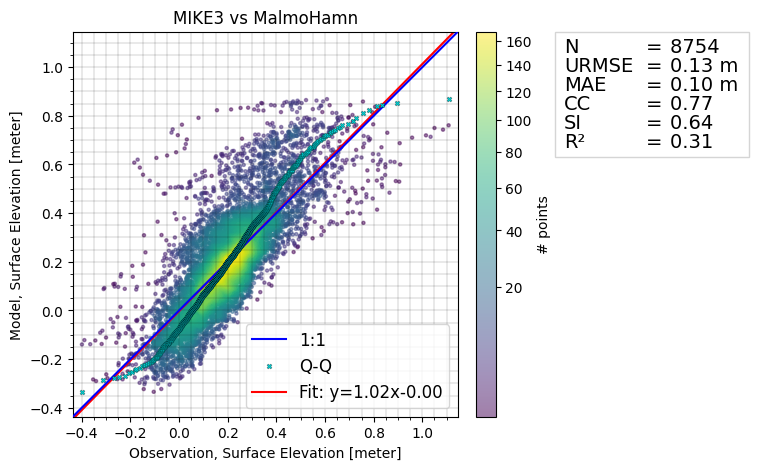

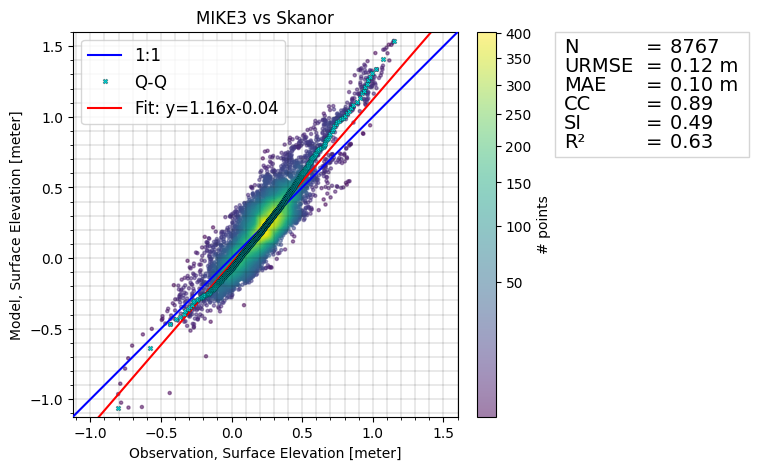

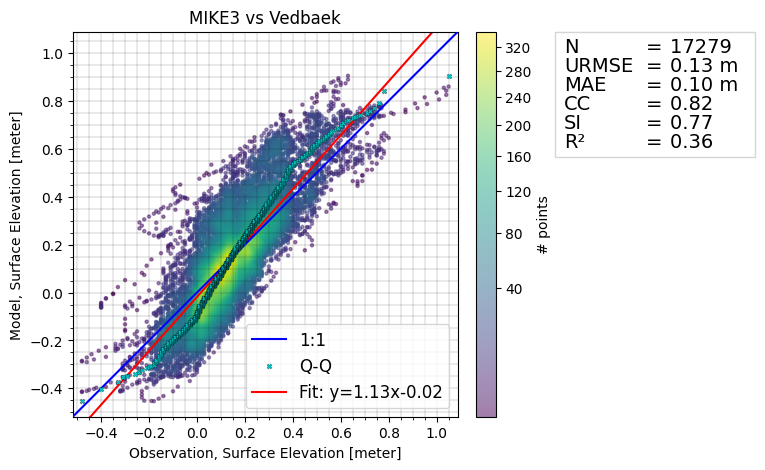

In [12]:
# n_points_shown = 20000
for cmp in cc:
    cmp.plot.scatter(skill_table=True, figsize=(6,5), bins=40);
    if save_png:
        plt.savefig(f"{fig_fldr}modelskill_comparison_{cmp.name}.png", bbox_inches='tight');